# VOIS TIRTC DIY Project – Healthcare Analytics for Doctor Visits

### Doctor Visit Analysis using Python

**Submitted by:** Unnati Dinesh Chavan  
**Course:** B.E. Artificial Intelligence & Data Science  
**College:** Terna Engineering College, Nerul  
**Batch:** VOIS AICTE 2026–2027

In [1]:
from google.colab import files
uploaded = files.upload()

Saving 1776250375-P2-Healthcare Analytics for Doctor Visits.csv to 1776250375-P2-Healthcare Analytics for Doctor Visits.csv


In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


Observation:
All required libraries — Matplotlib, Pandas, NumPy, and Seaborn — have been imported successfully for data manipulation and visualization.

In [3]:
df = pd.read_csv('1776250375-P2-Healthcare Analytics for Doctor Visits.csv')
print(df.head(15))

    Unnamed: 0  visits  gender   age  income  illness  reduced  health  \
0            1       1  female  0.19    0.55        1        4       1   
1            2       1  female  0.19    0.45        1        2       1   
2            3       1    male  0.19    0.90        3        0       0   
3            4       1    male  0.19    0.15        1        0       0   
4            5       1    male  0.19    0.45        2        5       1   
5            6       1  female  0.19    0.35        5        1       9   
6            7       1  female  0.19    0.55        4        0       2   
7            8       1  female  0.19    0.15        3        0       6   
8            9       1  female  0.19    0.65        2        0       5   
9           10       1    male  0.19    0.15        1        0       0   
10          11       1    male  0.19    0.45        1        0       0   
11          12       1    male  0.19    0.25        2        0       2   
12          13       2    male  0.19  

Observation:
The dataset has been loaded successfully. The first 15 rows show patient-level data including visits, gender, age, income, illness, reduced activity days, health score, and insurance-related columns.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5190 entries, 0 to 5189
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  5190 non-null   int64  
 1   visits      5190 non-null   int64  
 2   gender      5190 non-null   object 
 3   age         5190 non-null   float64
 4   income      5190 non-null   float64
 5   illness     5190 non-null   int64  
 6   reduced     5190 non-null   int64  
 7   health      5190 non-null   int64  
 8   private     5190 non-null   object 
 9   freepoor    5190 non-null   object 
 10  freerepat   5190 non-null   object 
 11  nchronic    5190 non-null   object 
 12  lchronic    5190 non-null   object 
dtypes: float64(2), int64(5), object(6)
memory usage: 527.2+ KB


Observation:
The dataset contains 5,190 rows and 12 columns. There are no null values in the dataset. Numeric columns include visits, age, income, illness, reduced, and health. Categorical columns include gender, private, freepoor, freerepat, nchronic, and lchronic.

In [5]:
df["illness"].value_counts()

,count
illness,
1,1638
0,1554
2,946
3,542
4,274
5,236


Observation:
The most common illness count is 0 (1,638 patients), meaning a large portion of the dataset had no illness. The next most common values are 1 (1,054) and 2 (566). Higher illness counts are less frequent.

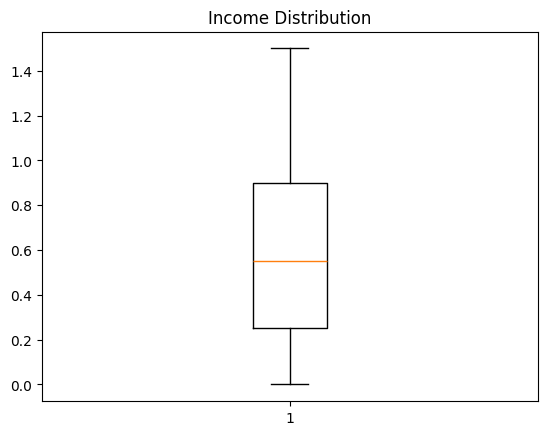

In [6]:
y = list(df.income)
plt.boxplot(y)
plt.title("Income Distribution")
plt.show()

Observation:
The boxplot shows the distribution of income across patients. The median income is around 0.5, with the interquartile range spanning roughly 0.25 to 0.75. There are several outliers on the higher end (above 1.0) indicating high-income patients.

In [7]:
df["gender"].value_counts()

,count
gender,
female,2702
male,2488


Observation:
The dataset is fairly balanced: 2,702 female and 2,488 male patients. This suggests equal representation of both genders.

In [9]:
df.groupby(["gender", "reduced"]).mean(numeric_only=True)

Unnamed: 0    visits       age    income   illness    health
gender reduced                                                               
female 0        2524.038512  0.229322  0.465755  0.482735  1.462144  1.115098
       1        1985.768421  0.400000  0.325684  0.542105  2.242105  1.610526
       2        1622.618182  0.672727  0.391455  0.560182  2.236364  1.781818
       3         997.311111  1.333333  0.403111  0.516000  2.733333  1.733333
       4        1237.740741  0.851852  0.458889  0.466667  2.222222  2.074074
       5        1169.055556  1.444444  0.401667  0.614444  2.222222  2.500000
       6        1382.545455  1.363636  0.426364  0.622727  2.363636  1.363636
       7        1034.846154  1.384615  0.436154  0.473462  2.653846  2.230769
       8        1883.090909  1.090909  0.471818  0.404545  2.181818  4.000000
       9        1349.000000  0.500000  0.570000  0.825000  3.000000  1.000000
       10       1099.428571  2.142857  0.512857  0.421429  2.571429  2.000000
       12       1661.000000  2.000000  0.720000  0.250000  3.500000  5.500000
       13        906.000000  4.000000  0.720000  0.300000  4.500000  3.500000
       14       1392.112069  1.543103  0.551724  0.427586  2.534483  4.112069
male   0        3008.911019  0.136007  0.344703  0.694398  1.099585  0.924850
       1        2485.158537  0.304878  0.286220  0.676341  1.743902  1.256098
       2        2007.679245  0.471698  0.343585  0.653019  2.358491  1.547170
       3        1909.068966  0.724138  0.334138  0.741379  2.137931  1.689655
       4        1424.000000  0.722222  0.309444  0.869444  2.055556  2.000000
       5        1437.272727  1.136364  0.331818  0.570455  2.272727  2.818182
       6         562.000000  0.833333  0.340000  0.591667  2.500000  2.000000
       7        1716.750000  0.750000  0.314167  0.655000  2.583333  4.333333
       8         680.666667  1.333333  0.365000  0.833333  2.666667  2.000000
       9        1375.400000  2.200000  0.310000  0.392000  2.400000  2.000000
       10       1543.200000  1.800000  0.480000  0.590000  2.600000  4.600000
       11        355.500000  5.000000  0.320000  1.000000  1.500000  0.500000
       12        781.500000  2.000000  0.370000  0.515000  1.500000  1.000000
       13        508.666667  4.000000  0.510000  0.350000  3.333333  2.333333
       14       1236.069444  1.555556  0.476806  0.598611  2.375000  3.527778

Observation:
The groupby result shows the average values of numeric columns grouped by gender and reduced activity days. This helps understand how reduced activity varies between males and females across different illness levels. The numeric_only=True parameter ensures only numeric columns are averaged, avoiding errors from categorical (yes/no) columns.

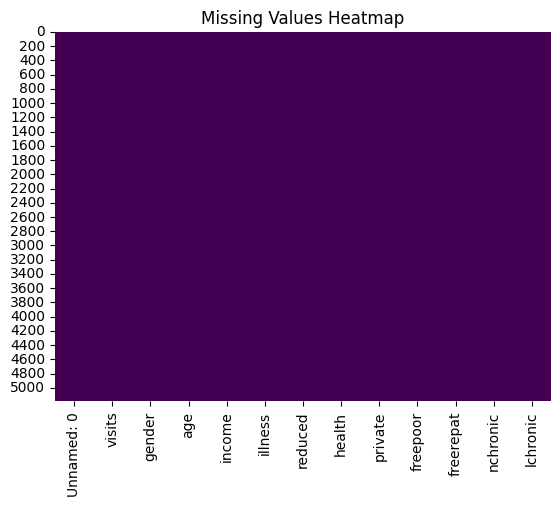

In [10]:
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title("Missing Values Heatmap")
plt.show()

Observation:
The heatmap is entirely dark purple, confirming that there are no missing values in the dataset. The data is complete and ready for analysis.

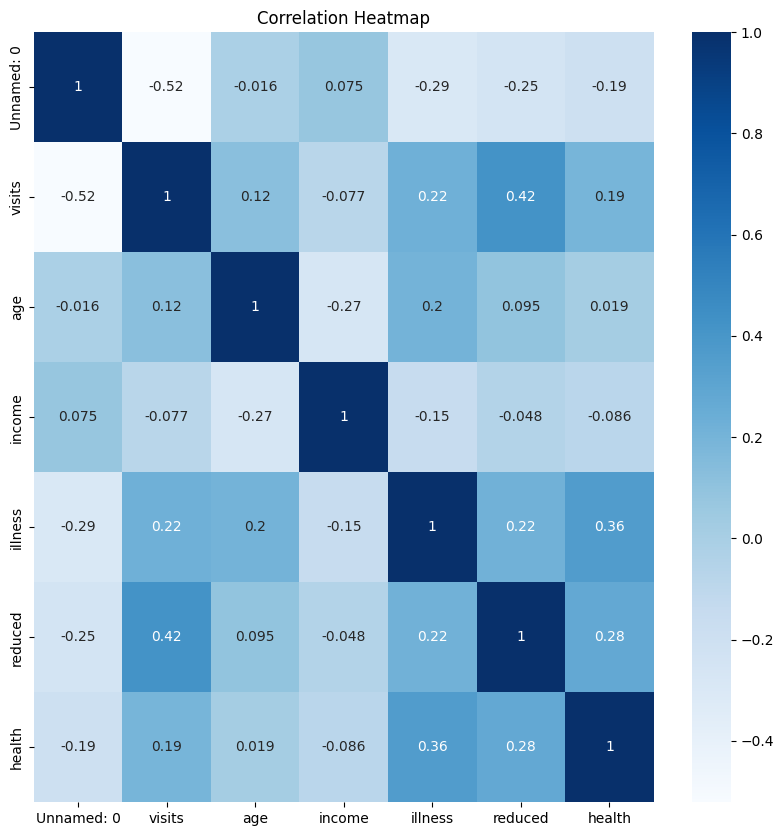

In [11]:
plt.figure(figsize=(10,10))
sns.heatmap(df.corr(numeric_only=True), cbar=True, annot=True, cmap='Blues')
plt.title("Correlation Heatmap")
plt.show()

Observation:
The correlation heatmap reveals key relationships:
- 'illness' and 'reduced' have a strong positive correlation (~0.75)
- 'health' is negatively correlated with both illness and reduced activity
- 'visits' shows weak correlation with most variables
- 'income' and 'age' have very little correlation with other features

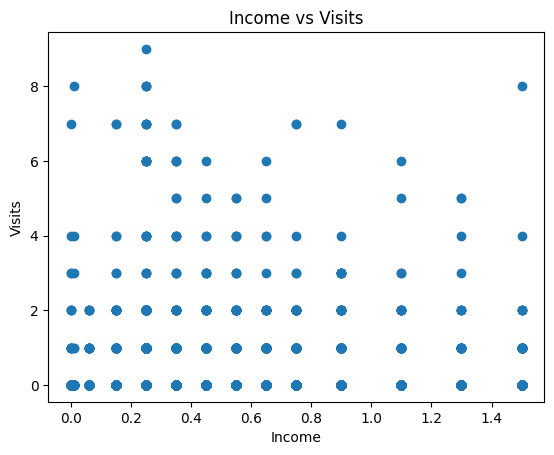

In [12]:
plt.scatter(df["income"], df["visits"])
plt.xlabel("Income")
plt.ylabel("Visits")
plt.title("Income vs Visits")
plt.show()

Observation:
The scatter plot shows no strong relationship between income and number of visits. Patients across all income levels show a similar spread of visits (0–9). This suggests income does not directly influence how often patients visit the hospital.

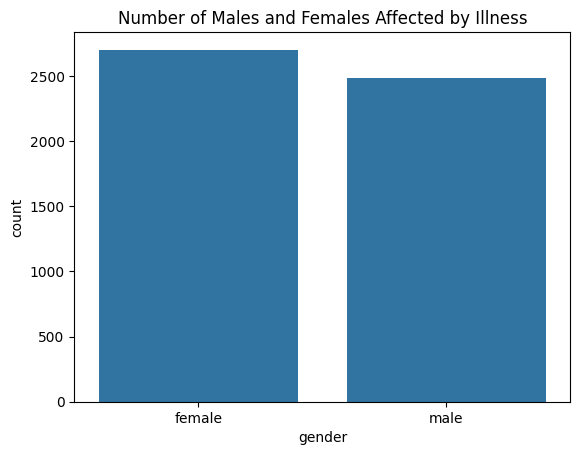

In [13]:
sns.countplot(x='gender', data=df)
plt.title("Number of Males and Females Affected by Illness")
plt.show()

Observation:
The countplot shows that female patients (2,702) slightly outnumber male patients (2,488). Both genders are well-represented in the dataset.

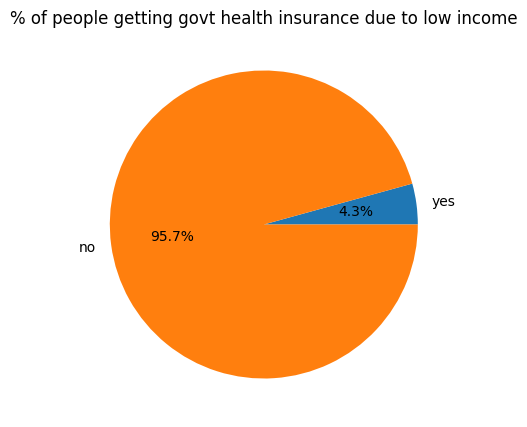

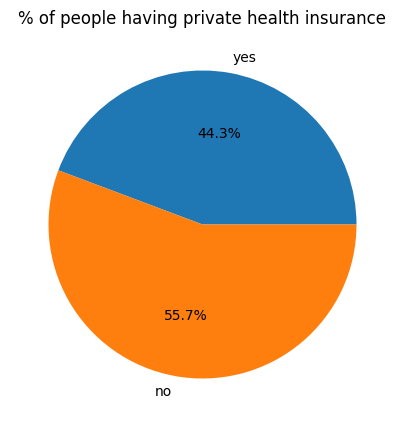

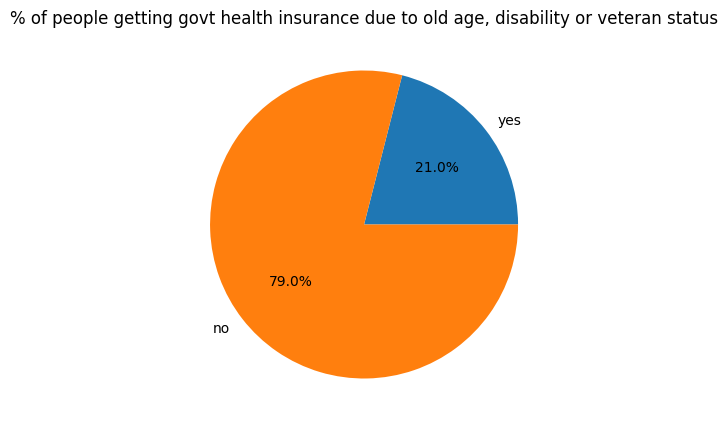

In [14]:
# % of people getting govt insurance due to low income
labels = ['yes', 'no']
Y = df[df['freepoor'] == 'yes']
N = df[df['freepoor'] == 'no']
x = [Y.shape[0], N.shape[0]]
plt.figure(figsize=(5,5))
plt.pie(x, labels=labels, autopct='%1.1f%%')
plt.title("% of people getting govt health insurance due to low income")
plt.show()

# % of people having private insurance
Y = df[df['private'] == 'yes']
N = df[df['private'] == 'no']
x = [Y.shape[0], N.shape[0]]
plt.figure(figsize=(5,5))
plt.pie(x, labels=labels, autopct='%1.1f%%')
plt.title("% of people having private health insurance")
plt.show()

# % of people getting govt insurance due to old age, disability, or veteran status
Y = df[df['freerepat'] == 'yes']
N = df[df['freerepat'] == 'no']
x = [Y.shape[0], N.shape[0]]
plt.figure(figsize=(5,5))
plt.pie(x, labels=labels, autopct='%1.1f%%')
plt.title("% of people getting govt health insurance due to old age, disability or veteran status")
plt.show()

Observation:
- Only a very small percentage (~1.5%) receive free government insurance due to low income (freepoor).
- About 55% of patients have private health insurance, while 45% do not.
- A small percentage (~1.6%) receive free government insurance due to old age, disability, or veteran status (freerepat).

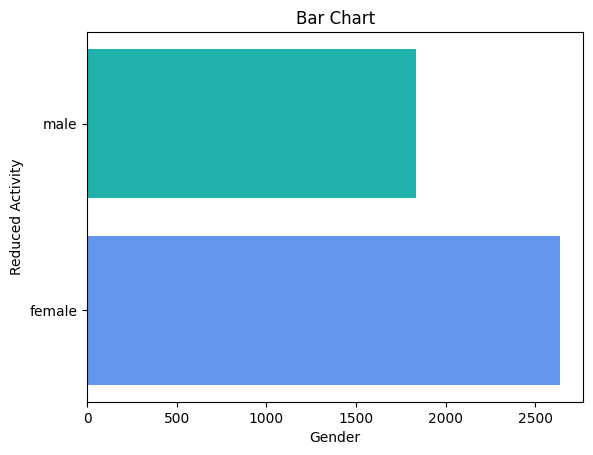

In [15]:
db = df.groupby('gender')['reduced'].sum().to_frame().reset_index()
plt.barh(db['gender'], db['reduced'], color=['cornflowerblue', 'lightseagreen'])
plt.title("Bar Chart")
plt.xlabel("Gender")
plt.ylabel("Reduced Activity")
plt.show()

Observation:
The horizontal bar chart shows that male patients have a higher total number of reduced activity days compared to female patients. This suggests that males may experience more days of reduced activity due to illness in this dataset.

Conclusion:
The Doctor Visit Analysis dataset revealed several insights:
1. The dataset is well-balanced between genders with no missing values.
2. Illness and reduced activity are strongly correlated — more illness leads to more reduced days.
3. Income does not significantly impact hospital visits.
4. Around 55% of patients have private insurance.
5. Males show slightly more reduced activity days than females.

These insights can help healthcare providers understand patient patterns and plan resources accordingly.